# Hourly Crypto Algo-Trading - End-to-End Workflow

This notebook **calls the functions from the `.py` modules** in `src/` and shows
the complete workflow:

1. `src/download.py`  - pull hourly klines + funding rates (Binance) and
   macro series (Yahoo Finance), *incrementally*
2. `src/transform.py` - combine into one dataset, engineer 40 features, build targets
3. `src/train.py`     - tune LogReg / DecisionTree / RandomForest / XGBoost,
   pick a probability threshold on validation
4. `src/simulate.py`  - 4 vector strategies + 1 exact iterative simulation
   (reinvestment), benchmark vs buy-and-hold BTC
5. Show the **latest new trades**

Two modes (rubric: two regimes for the system):
- **file mode** (default): runs from local parquet files - fast, reproducible
- **download mode**: first refreshes data from the APIs (used by the daily cron job)

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# make the project root importable when the notebook runs from notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    sys.path.insert(0, str(ROOT.parent))
    ROOT = ROOT.parent

import pandas as pd
from src import config, pipeline

pd.set_option("display.width", 140)
print("project root:", config.PROJECT_DIR)

project root: E:\GitHub\stock-markets-analytics-zoomcamp\projects\hourly-crypto


## 1. Run the full pipeline (file mode)

`pipeline.run` executes download (skipped in file mode) -> transform -> train ->
simulate(valid, for strategy selection) -> simulate(test) -> latest trades.
To refresh data from the APIs first, use `pipeline.run(source="download")`.

In [2]:
# full end-to-end run (train takes ~10 minutes the first time)
pipeline.run(source="file")

[pipeline] source=file: using local data (no API calls)


loaded 1,865,048 rows / 42 symbols (3s)


combined: 1,865,048 rows x 53 cols (19s)



saved -> E:\GitHub\stock-markets-analytics-zoomcamp\projects\hourly-crypto\data\combined.parquet
window: 2021-01-01 00:00:00+00:00 .. 2026-11-15 11:00:00+00:00
features: 40 numeric + dummies ['symbol', 'hour_bucket']
target target_24h (growth>1.0): train class share = 0.494, all = 0.486
rows with target = 1,864,040 / 1,865,048


rows: train=965,141 valid=367,887 test=505,512 | features=92


tuning logreg...


... (16 outputs left out)

sim3_rf_longs: {'total_return': 0.4849, 'cagr': 0.3336, 'sharpe': 0.769, 'max_drawdown': -0.4334, 'n_trades': 42, 'trades_per_day': 0.08}


sim4_rf_advanced: {'total_return': 0.0881, 'cagr': 0.0634, 'sharpe': 0.355, 'max_drawdown': -0.3823, 'n_trades': 185, 'trades_per_day': 0.37}


sim5_rf_exact {'stop_loss': None, 'max_hold': None, 'regime_min': 0.0178002822079937}: {'total_return': -0.1097, 'cagr': -0.0812, 'sharpe': -0.164, 'max_drawdown': -0.3762, 'n_trades': 137, 'trades_per_day': 0.27}
benchmark_btc: {'total_return': -0.3735, 'cagr': -0.2886, 'sharpe': -0.625, 'max_drawdown': -0.5377, 'n_trades': 1, 'trades_per_day': 0.0}



wrote simulation_results_test.csv, equity curves, trades, ticker precision

latest trades @ 2026-11-14 11:00:00+00:00 (0 signals) -> outputs/latest_trades.csv

=== test-set strategy summary ===
                   total_return    cagr  sharpe  max_drawdown  n_trades  trades_per_day
sim1_rf_long             0.1248  0.0894   0.438       -0.3829     382.0            0.76
sim2_rf_probasize        0.1249  0.0895   0.438       -0.3830     382.0            0.76
sim3_rf_longs            0.4849  0.3336   0.769       -0.4334      42.0            0.08
sim4_rf_advanced         0.0881  0.0634   0.355       -0.3823     185.0            0.37
sim5_rf_exact           -0.1097 -0.0812  -0.164       -0.3762     137.0            0.27
benchmark_btc           -0.3735 -0.2886  -0.625       -0.5377       1.0            0.00

[pipeline] done in 746s


## 2. Strategy results

In [3]:
res_test = pd.read_csv(config.OUTPUT_DIR / "simulation_results_test.csv", index_col=0)
res_valid = pd.read_csv(config.OUTPUT_DIR / "simulation_results_valid.csv", index_col=0)
print("VALID  (2024-07 .. 2025-07)")
display(res_valid)
print("TEST   (2025-07 .. 2026-11)")
display(res_test)

VALID  (2024-07 .. 2025-07)


,total_return,cagr,sharpe,max_drawdown,n_trades,trades_per_day
sim1_rf_long,0.7025,0.7031,1.274,-0.2743,357.0,0.98
sim2_rf_probasize,0.7058,0.7064,1.278,-0.2745,357.0,0.98
sim3_rf_longs,0.0345,0.0346,0.444,-0.6839,43.0,0.12
sim4_rf_advanced,0.8510,0.8517,1.426,-0.3045,144.0,0.39
sim5_rf_exact,0.8558,0.8566,1.629,-0.2863,122.0,0.33
benchmark_btc,0.7018,0.7025,1.295,-0.3097,1.0,0.00


TEST   (2025-07 .. 2026-11)


,total_return,cagr,sharpe,max_drawdown,n_trades,trades_per_day
sim1_rf_long,0.1248,0.0894,0.438,-0.3829,382.0,0.76
sim2_rf_probasize,0.1249,0.0895,0.438,-0.3830,382.0,0.76
sim3_rf_longs,0.4849,0.3336,0.769,-0.4334,42.0,0.08
sim4_rf_advanced,0.0881,0.0634,0.355,-0.3823,185.0,0.37
sim5_rf_exact,-0.1097,-0.0812,-0.164,-0.3762,137.0,0.27
benchmark_btc,-0.3735,-0.2886,-0.625,-0.5377,1.0,0.00


In [4]:
import json
with open(config.OUTPUT_DIR / "metrics.json") as f:
    metrics = json.load(f)
rows = {k: {"val_auc": v["val_auc"], "test_auc": v["test_auc"],
            "threshold": v["threshold"], "val_precision": v["val_precision"],
            "test_precision": v["test_precision"],
            "test_signal_share": v["test_signal_share"]}
        for k, v in metrics["models"].items()}
pd.DataFrame(rows).T

,val_auc,test_auc,threshold,val_precision,test_precision,test_signal_share
logreg,0.507155,0.512021,0.50,0.532712,0.484645,0.020935
dt,0.515441,0.507422,0.67,0.513533,0.469826,0.405520
rf,0.523995,0.528991,0.65,0.619391,0.599472,0.020981
xgb,0.523581,0.524762,0.80,0.547812,0.544981,0.046705


## 3. Equity curves vs buy-and-hold BTC (test set)

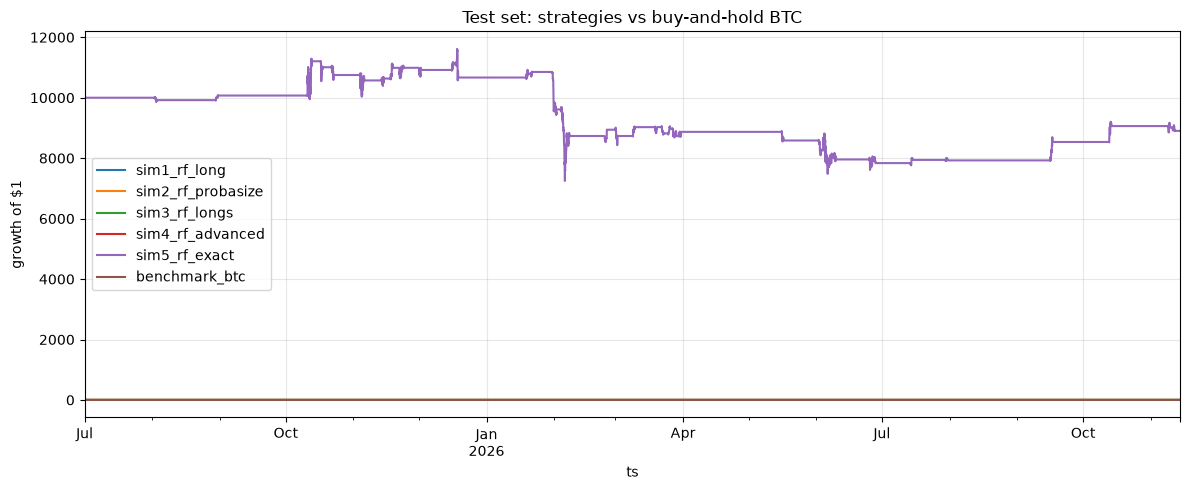

In [5]:
import matplotlib.pyplot as plt

eq = pd.read_parquet(config.OUTPUT_DIR / "equity_curves_test.parquet")
ax = eq.plot(figsize=(12, 5), title="Test set: strategies vs buy-and-hold BTC")
ax.set_ylabel("growth of $1")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Latest new trades (what to execute now)

In [6]:
pd.read_csv(config.OUTPUT_DIR / "latest_trades.csv")

,ts,symbol,signal_probability,action


## 5. EDA - target and feature/target correlations

target_24h base rate: 0.486 | rows: 1,865,048 | symbols: 42


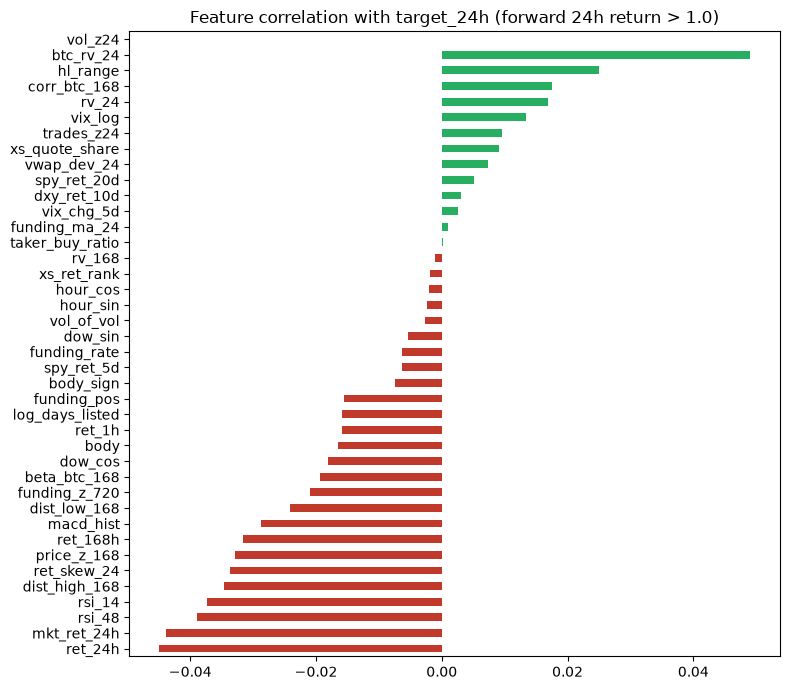

,corr_with_target,target_24h
ret_24h,-0.044961,NaN
mkt_ret_24h,-0.043895,NaN
rsi_48,-0.038938,NaN
rsi_14,-0.037368,NaN
dist_high_168,-0.034603,NaN
ret_skew_24,-0.033673,NaN
price_z_168,-0.032833,NaN
ret_168h,-0.031665,NaN


In [7]:
df = pd.read_parquet(config.DATA_DIR / "combined.parquet")
print("target_24h base rate:", round(df["target_24h"].mean(), 3),
      "| rows:", f"{len(df):,}", "| symbols:", df["symbol"].nunique())

from src.transform import NUMERIC_FEATURES, TARGET
corr = df[NUMERIC_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
corr.plot(kind="barh", ax=ax, color=["#c0392b" if v < 0 else "#27ae60" for v in corr])
ax.set_title("Feature correlation with target_24h (forward 24h return > 1.0)")
plt.tight_layout()
plt.show()
pd.DataFrame({"corr_with_target": corr}).head(8).join(
    corr.tail(8), lsuffix="_low", rsuffix="_high")

## 6. Deep analysis: precision by ticker (debug wrong predictions)

,n_rows,base_rate,signal_share,precision
symbol,,,,
JUPUSDT,12036.0,0.481057,0.004320,0.884615
WIFUSDT,12036.0,0.459704,0.008890,0.803738
DOGEUSDT,12036.0,0.468013,0.024842,0.698997
1000PEPEUSDT,12036.0,0.466600,0.010884,0.687023
ENAUSDT,12036.0,0.447408,0.009721,0.683761
RUNEUSDT,12036.0,0.482635,0.022848,0.672727
UNIUSDT,12036.0,0.483882,0.022183,0.662921
LDOUSDT,12036.0,0.483383,0.013377,0.658385


,n_rows,base_rate,signal_share,precision
symbol,,,,
TIAUSDT,12036.0,0.466102,0.010884,0.534351
BTCUSDT,12036.0,0.504071,0.032818,0.526582
DOTUSDT,12036.0,0.446411,0.026005,0.520767
OPUSDT,12036.0,0.468096,0.024427,0.500000
SOLUSDT,12036.0,0.491775,0.029495,0.461972


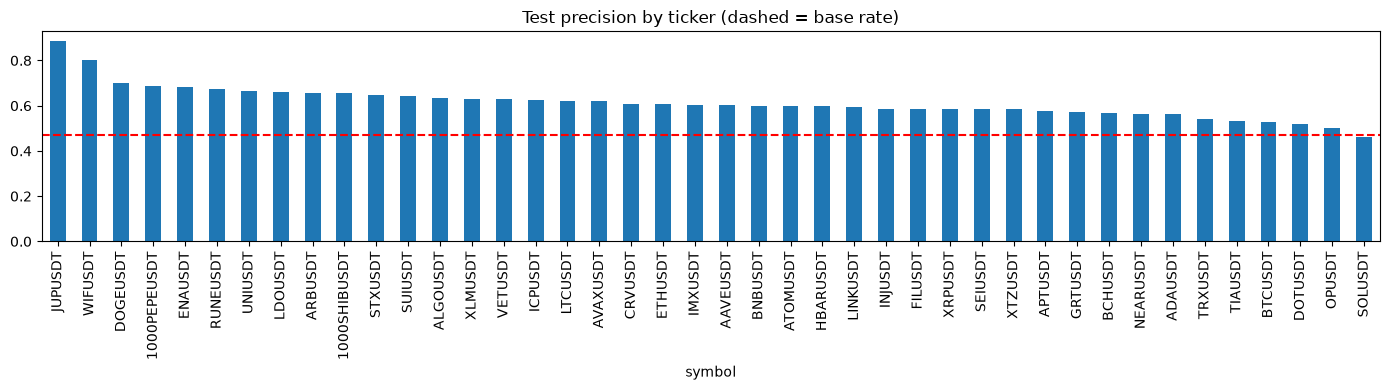

In [8]:
tick = pd.read_csv(config.OUTPUT_DIR / "ticker_precision_test.csv", index_col=0)
tick = tick.sort_values("precision", ascending=False)
display(tick.head(8))
display(tick.tail(5))
ax = tick["precision"].dropna().plot(kind="bar", figsize=(14, 4),
                                     title="Test precision by ticker (dashed = base rate)")
ax.axhline(tick["base_rate"].mean(), color="red", ls="--")
plt.tight_layout()
plt.show()

## 7. Feature importance (tree models)

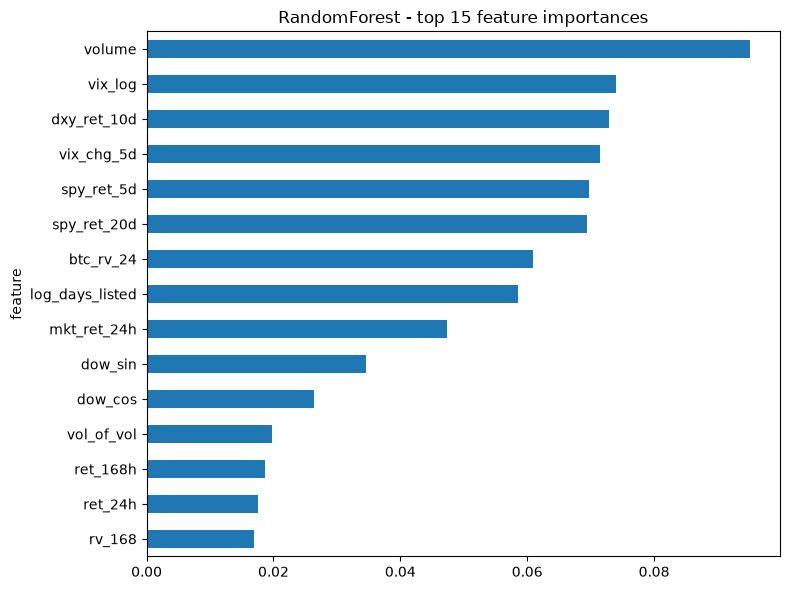

In [9]:
imp = pd.read_csv(config.OUTPUT_DIR / "feature_importance.csv")
imp = imp[imp["model"] == "rf"].nlargest(15, "importance")
ax = imp.iloc[::-1].plot(x="feature", y="importance", kind="barh",
                         legend=False, figsize=(8, 6),
                         title="RandomForest - top 15 feature importances")
plt.tight_layout()
plt.show()

## 8. Signal economics (the key debugging finding)

The signal is positive-EV per trade, but **hourly re-weighting churned the
portfolio to death in fees**. All deployed strategies therefore decide once a
day (00:00 UTC) and hold for 24h.

In [10]:
p = pd.read_parquet(config.OUTPUT_DIR / "predictions_with_sims_test.parquet")
g = pd.read_parquet(config.DATA_DIR / "combined.parquet",
                    columns=["ts", "symbol", "growth_future_24h"])
p = p.merge(g, on=["ts", "symbol"], how="left")
thr = metrics["models"]["rf"]["threshold"]
sig = p[f"proba_rf"] >= thr
fwd = p["growth_future_24h"] - 1
pd.DataFrame({
    "n_signals": [int(sig.sum())],
    "share_of_rows": [round(sig.mean(), 4)],
    "mean_fwd24h_signal_%": [round(fwd[sig].mean() * 100, 3)],
    "mean_fwd24h_nosignal_%": [round(fwd[~sig].mean() * 100, 3)],
    "winrate_signal": [round((fwd[sig] > 0).mean(), 3)],
    "ev_after_costs_%": [round(fwd[sig].mean() * 100 - 0.30, 3)],
})

,n_signals,share_of_rows,mean_fwd24h_signal_%,mean_fwd24h_nosignal_%,winrate_signal,ev_after_costs_%
0,10606,0.021,1.162,-0.118,0.599,0.862
